# Imports

In [90]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
import copy
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from torch import nn
import pandas as pd
import torch
from sklearn.metrics import balanced_accuracy_score, recall_score

# Overview
### Model Pipeline
- Preprocessing
- Model Definitions
- Hyperparameter Tuning
- Validation
### Execution Main
* Access data
* Run preprocessing
* Define hyperparameters to explore
* Define hyperparameter training routine
* Run training routine
* Run testing routine
### Validation Execution


# Model Pipeline
- Preprocessing
-- The dataframe is split up by engine unit. Training data is scaled. Training and test datasets are returned, while the validation dataset indexes are used to return a validation dataframe. Input and output size objects are returned to make neural net input and output layers easier to adjust.

In [91]:
def prepare_data(df, target="hpt_temp_eff", health_value=1.0, seed=42):
    """
    Build train, validation, and test TensorDatasets for one regression target,
    using only rows where health_status == health_value.

    This data preparation was a breakthrough.

    - Splits by engine `unit`, so no unit appears in more than one split.
      (Rows from the same unit are near-duplicates of each other, so a
      random row split leaks.)
    - Scalers are fit on the training rows only, then applied to validation and test.
    - `unit`, `cycle`, `health_status` and the target are not used as features.
    `df` must still contain the `unit` column.

    - Validation dataset is reconstituted with both health status indications

    Output: train_ds, full_validation_df, test_ds, x_scaler, y_scaler, inputSize, outputSize
    """
    data = df[df["health_status"] == health_value]

    groups = data["unit"].to_numpy()  # array needed to find group indices
    y = data[[target]].to_numpy()
    x = data.drop(columns=["unit", "cycle", "health_status", target]).to_numpy()

    def split_units(idx, test_size):
        '''
        https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html
        scikit-learn class 'GroupShuffleSplit' passes the class object into a generator to split the dataset by the index of the relevant groups
        Input: idx = array of indices, test_size = proportion to split (80/20)
        Output: sets of indices to split the original data on
        '''
        gss_obj = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        train_idx, test_idx = next(gss_obj.split(X=idx, groups=groups[idx]))
        return idx[train_idx], idx[test_idx]

    # 80% to trainval, 20% to test
    # 80% of trainval to train, 20% of trainval to val
    # trainval is not reused
    trainval, test = split_units(np.arange(len(data)), 0.2)
    train, val = split_units(trainval, 0.2)

    x_scaler = StandardScaler().fit(x[train]) # only the training dataset rows are scaled
    y_scaler = StandardScaler().fit(y[train])

    def make(idx):
        '''
        Convert dataframes into tensors
        '''
        return TensorDataset(
            torch.as_tensor(x_scaler.transform(x[idx]), dtype=torch.float32),
            torch.as_tensor(y_scaler.transform(y[idx]), dtype=torch.float32),
        )

    train_ds = make(train)
    val_ds = make(val)
    test_ds = make(test)
    inputSize = x.shape[1]
    outputSize = y.shape[1]

    # validation dataset is picked out of the original dataset for use later
    val_dframe = df.iloc[val] # health status unscreened
    val_mask = df['unit'].isin(val_dframe['unit'].unique())
    full_validation_df = df[val_mask]

    return train_ds, full_validation_df, test_ds, x_scaler, y_scaler, inputSize, outputSize

- Model Definitions
-- Six models are defined, Logistic Regression being the baseline. The CELU activation function was settled on. It is one hyperparameter that the pilgrim class does not explore.

In [92]:
class MyFFN(nn.Module):

    def __init__(self, model, inputSize, outputSize):
        super().__init__()

        self.name = model

        if model == 'LogisticRegression':
            self.net = nn.Sequential(
                nn.Linear(inputSize, outputSize)
            )

        elif model == 'SmallMLP':
            self.net = nn.Sequential(
                nn.Linear(inputSize, 16),
                nn.CELU(),

                nn.Linear(16, 8),
                nn.CELU(),

                nn.Linear(8, outputSize)
            )

        elif model == 'MediumMLP':
            self.net = nn.Sequential(
                nn.Linear(inputSize, 64),
                nn.CELU(),

                nn.Linear(64, 32),
                nn.CELU(),

                nn.Linear(32, 16),
                nn.CELU(),

                nn.Linear(16, outputSize)
            )

        elif model == 'LargeMLP':
            self.net = nn.Sequential(
                nn.Linear(inputSize, 128),
                nn.CELU(),

                nn.Linear(128, 64),
                nn.CELU(),

                nn.Linear(64, 32),
                nn.CELU(),

                nn.Linear(32, 16),
                nn.CELU(),

                nn.Linear(16, 8),
                nn.CELU(),

                nn.Linear(8, 4),
                nn.CELU(),

                nn.Linear(4, outputSize)
            )

        elif model == 'DropoutMLP':
            self.net = nn.Sequential(
                nn.Linear(inputSize, 64),
                nn.CELU(),
                nn.Dropout(0.3),

                nn.Linear(64, 32),
                nn.CELU(),
                nn.Dropout(0.3),

                nn.Linear(32, outputSize)
            )

        elif model == 'WideMLP':
            self.net = nn.Sequential(
                nn.Linear(inputSize, 128),
                nn.CELU(),

                nn.Linear(128, 128),
                nn.CELU(),

                nn.Linear(128, 128),
                nn.CELU(),

                nn.Linear(128, outputSize)
            )

        else:
            raise ValueError(f'Unknown model type: {model}')

    def forward(self, x):
        return self.net(x)

- Hyperparameter Tuning
-- Trains and tests all feed forward neural networks in a list. It tries all loss functions in a list and allows epochs, optimizer and optimizer kwargs to be passed in as class arguments. The cpu or cuda can be passed in to change the processing machine (if possible).

In [93]:
class Pilgrim:
    """
    Trains a family of feed-forward networks under each of several loss
    functions (criterion argument), then compares them on a held-out set.

    Workflow:
        p = Pilgrim(...)
        train_history = p.run_training()      # one dict per criterion
        eval_results = p.run_evaluation()      # one dict per criterion
    """

    #model_names = ["LogisticRegression", "SmallMLP", "MediumMLP",
    #               "LargeMLP", "DropoutMLP", "WideMLP"
    #               ]
    model_names = ["LogisticRegression"]

    def __init__(self, train_search, test_search, inputSize, outputSize,
                 criterion: list, target, optimizer_class=torch.optim.AdamW,
                 optimizer_kwargs=None, numEpochs=200, batch_size=32,
                 metrics=None, device=None, seed=0):

        if not criterion:
            raise ValueError("Provide at least one criterion.")

        self.train_search = train_search
        self.test_search = test_search
        self.inputSize = inputSize
        self.outputSize = outputSize
        self.criterion = criterion
        self.optimizer_class = optimizer_class
        self.optimizer_kwargs = optimizer_kwargs or {}  # Adjust learning rate as needed
        self.numEpochs = numEpochs
        self.batch_size = batch_size
        # Common metrics so models trained with different losses are comparable
        self.metrics = metrics or {"MSE": nn.MSELoss(), "MAE": nn.L1Loss()}
        # This class is a memory monster
        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.seed = seed  # Leave at 0
        self.trained_models = None  # filled by run_training() to pass models along
        self.target = target

    # get data here
    def _training_iterators(self):
        """Fresh data loaders for each call, so every run sees the same batch order."""
        gen = torch.Generator().manual_seed(self.seed) # seeding the generator for DataLoader
        # Each call gives the batch order
        trainIterator = DataLoader(self.train_search, batch_size=self.batch_size,
                                   shuffle=True, generator=gen)
        testIterator = DataLoader(self.test_search, batch_size=self.batch_size,
                                  shuffle=False)
        return trainIterator, testIterator

    # models
    def _FFN_nexus(self) -> list:
        """Build every network. Seeded so initial weights are reproducible."""
        torch.manual_seed(self.seed)
        # device is 'cpu' or 'cuda'
        return [MyFFN(model=name, inputSize=self.inputSize, outputSize=self.outputSize)
                .to(self.device)for name in self.model_names
                ]

    # training
    def _epoch_training(self, model, trainIterator, optimizer, epoch: int, criterion_number: int) -> dict:

        criterion = self.criterion[criterion_number]
        model.train()
        total = 0.0
        count = 0

        for domain_, range_ in trainIterator:  # domain_ and range_ are generically named for x and y
            domain_ = domain_.to(self.device)
            range_ = range_.to(self.device)
            optimizer.zero_grad()
            loss = criterion(model(domain_), range_)
            loss.backward()
            optimizer.step()
            # weight by batch size
            total += loss.item() * domain_.size(0)   # epoch’s average loss as an exact per-sample average
            count += domain_.size(0)

        return {
            "model": model.name,
            "criterion": type(criterion),  # since the loss function is a class, the type is it's class name
            "epoch": epoch + 1,
            "training_loss": total / count,
        }

    def run_training(self) -> tuple:
        """
        Returns one dict per criterion: {model_name: [per-epoch result dicts]}.
        Each (model, criterion) pair gets its own deep copy and optimizer, so
        criteria never contaminate each other.
        """
        models = self._FFN_nexus()  # list of models
        results = [{} for _ in self.criterion]  # {empty} per loss function (criterion)
        self.trained_models = [{} for _ in self.criterion]  # populate the class variable

        for base_model in models: # Train each model once per loss function
            if base_model is None:
                continue

            for n in range(len(self.criterion)):
                torch.manual_seed(self.seed)        # reproducible dropout masks
                trainIterator, _ = self._training_iterators()
                model = copy.deepcopy(base_model)   # same init for every criterion
                # optimizer does not change. This just passes in the optimizer arguments
                optimizer = self.optimizer_class(model.parameters(), **self.optimizer_kwargs)

                history = []
                for epoch in range(self.numEpochs):
                    epoch_result = self._epoch_training(model, trainIterator, optimizer, epoch, criterion_number=n)
                    history.append(epoch_result)

                results[n][model.name] = history
                self.trained_models[n][model.name] = model

        return tuple(results)

    # evaluation
    @torch.no_grad()
    def _evaluate(self, model, testIterator, fn) -> float:
        model.eval()
        total = 0.0
        count = 0
        for domain_, range_ in testIterator:
            domain_ = domain_.to(self.device)
            range_ = range_.to(self.device)
            # epoch’s average loss as an exact per-sample average
            total += fn(model(domain_), range_).item() * domain_.size(0)
            count += domain_.size(0)
        return total / count

    def run_evaluation(self) -> tuple:
        """
        Returns one dict per criterion:
            {model_name: {'criterion_loss': ..., 'MSE': ..., 'MAE': ...}}
        'criterion_loss' is the loss the model was trained with; the other
        metrics are shared across criteria.
        """

        _, testIterator = self._training_iterators()
        out = [{} for _ in self.criterion]

        for n, crit in enumerate(self.criterion):
            for name, model in self.trained_models[n].items():
                row = {"criterion_loss": self._evaluate(model, testIterator, crit)}
                for metric_name, fn in self.metrics.items():
                    row[metric_name] = self._evaluate(model, testIterator, fn)
                out[n][name] = {k: round(v, 6) for k, v in row.items()}

        return tuple(out)

    # inspection
    @torch.no_grad()
    def inspect_predictions(self, criterion_number: int, model_name: str, y_scaler=None, n: int = 10):
        """Print actual vs predicted on a test batch."""
        model = self.trained_models[criterion_number][model_name].eval()
        _, testIterator = self._training_iterators()
        domain_, range_ = next(iter(testIterator))

        pred = model(domain_.to(self.device)).cpu().numpy()
        actual = range_.cpu().numpy()
        if y_scaler is not None:  # reverse standardization
            pred = y_scaler.inverse_transform(pred)
            actual = y_scaler.inverse_transform(actual)

        comparison = zip(actual[:n].round(4), pred[:n].round(4))

        for a, p in comparison:
            print(f"Actual: {a} | Predicted: {p}")

    @torch.no_grad()
    def save_model(self, criterion_number: int, model_name: str):
        model = self.trained_models[criterion_number][model_name]
        criterion_name = self.criterion[criterion_number]
        torch.save(model, f'{self.target}_{model_name}_{criterion_name}')
        print(f'Model saved as {self.target}_{model_name}_{criterion_name}')

# Validation
  *   Using the feature importances determined by the tree ensemble, there is a predictor of health status for most engine sections.
  *   Most sections have more than one metric for efficiency.
  * The goal of the validation portion is to use the three engine units not utilized in training, or testing, to determine if the threshold of degredation has been crossed by specific efficiency metrics.
  * High pressure turbine and engine pressure ratio are typical indicators of engine degredation. They both capture multi-system degredation. Fan stall margin (SmFan), on the other hand, should only indicate fan degredation.



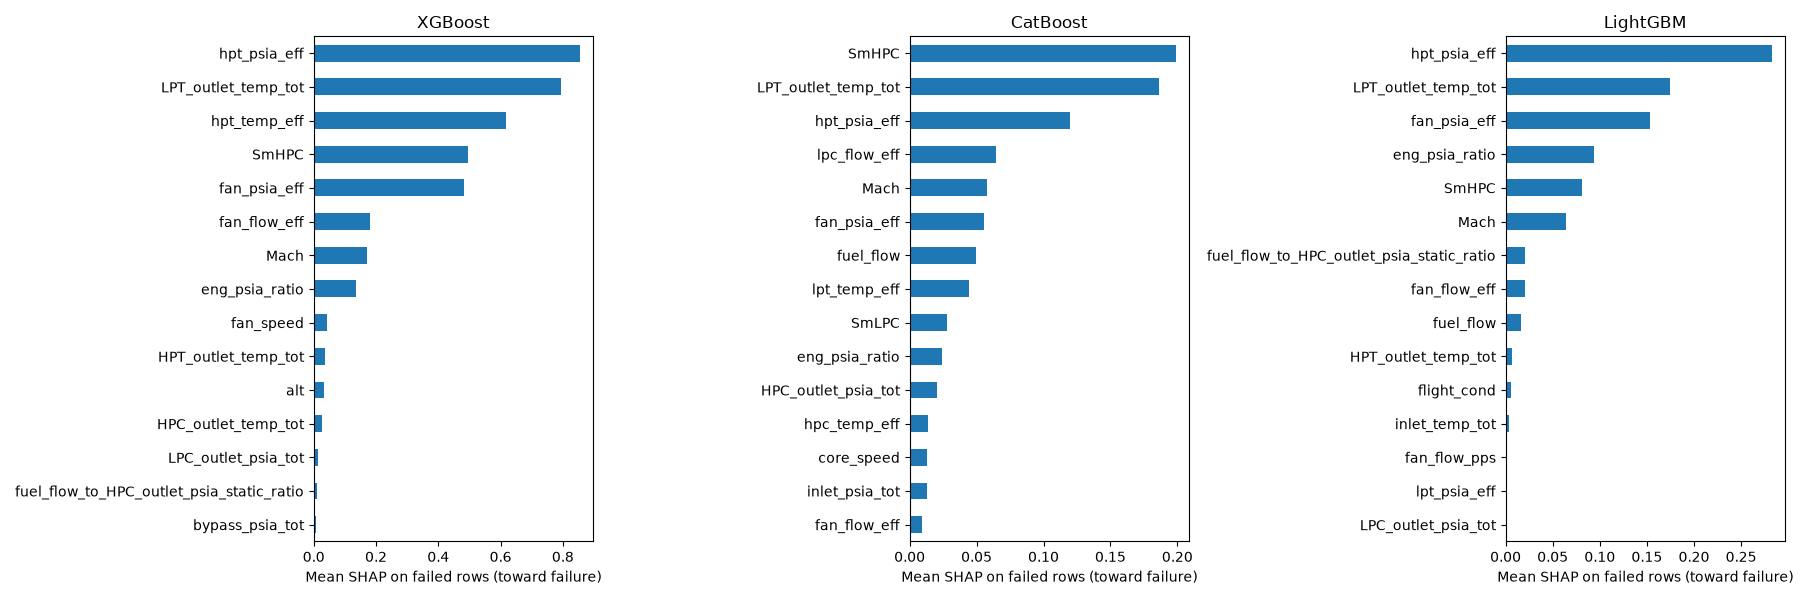
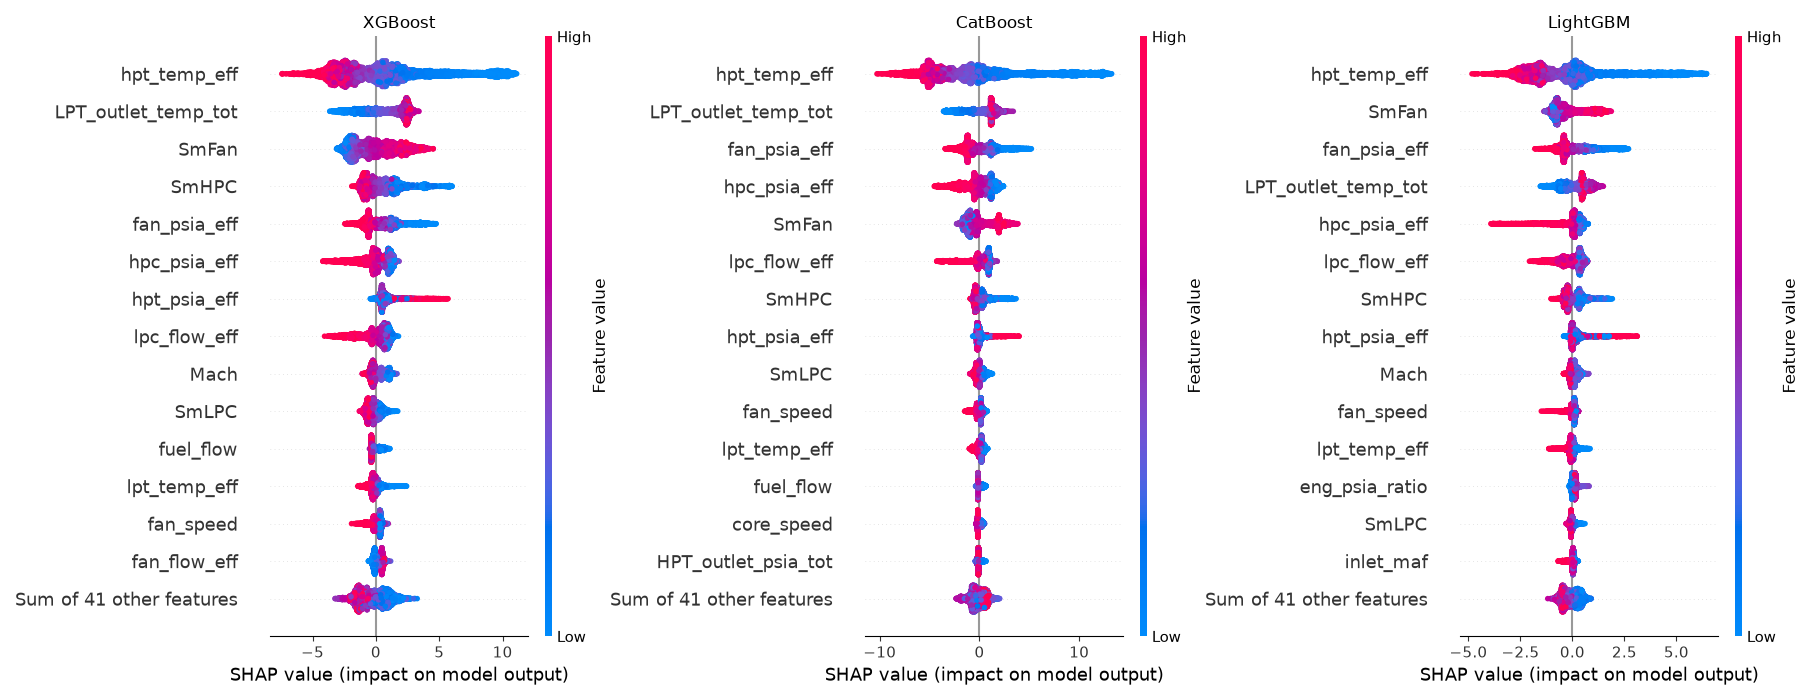

In [94]:
def report_health_status(model_path, val_dframe, train_data, x_scaler, y_scaler,
                         target="hpt_temp_eff", percentile=95, n_show=10):
    """
    Predict health_status from a model trained on `target` using healthy
    (health_status == 1.0) rows only. Rows the model fits poorly are labelled 0.

    Returns (results_df, threshold).
    """
    # Load the saved model in eval mode
    try:
        model = torch.load(model_path, map_location="cpu", weights_only=False).eval()
    except FileNotFoundError:
        raise FileNotFoundError(f"No model at {model_path}.")

    # Error threshold from the training data (healthy rows only)
    x_tr, y_tr = train_data.tensors
    with torch.no_grad():
        train_err = (model(x_tr) - y_tr).abs().numpy().ravel()
    threshold = np.percentile(train_err, percentile)

    # Run on the validation engines (both health statuses)
    feature_cols = [c for c in val_dframe.columns if c not in ("unit", "cycle", "health_status", target)]

    x_val = torch.tensor(x_scaler.transform(val_dframe[feature_cols].to_numpy()), dtype=torch.float32)
    y_val = y_scaler.transform(val_dframe[[target]].to_numpy())

    with torch.no_grad():
        err = np.abs(model(x_val).numpy() - y_val).ravel()

    # Report
    results = val_dframe[["unit", "cycle"]].copy()
    results["actual"] = val_dframe["health_status"].astype(int).to_numpy()
    results["predicted"] = (err <= threshold).astype(int)  # big error -> 1 (healthy)
    results["err"] = err

    return results, threshold

In [95]:
def save_model_results_csv(eval_results, path="model_results.csv"):
    """
    Writes one row per (criterion, model) to a CSV and returns the DataFrame.
    The training and test iterators need to be active for this to run.
    """
    rows = []
    for n, result in enumerate(eval_results):
        crit_name = type(criteria[n])
        for name, row in result.items():
            rows.append({"criterion": crit_name,
                         "model": name,
                         "train_loss": train_history[n][name][-1]["training_loss"],
                         **{f"test_{k}": v for k, v in row.items()}
                         })

    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    return df

In [96]:
def inspect_results (model_path, metric,
                     val_dframe, train_data,
                     x_scaler, y_scaler):
  '''
  Print out the accuracy of the same model trained on different targets.
  '''
  results, threshold = report_health_status(
      model_path=model_path,
      val_dframe=val_dframe,
      train_data=train_data,
      x_scaler=x_scaler,
      y_scaler=y_scaler
  )

  print(f'Metric: {metric}')
  print(f"Threshold (95th pct of training error): {threshold:.4f}")
  print(f"Accuracy: {(results.actual == results.predicted).mean():.4f}")
  print(pd.crosstab(results.actual, results.predicted, rownames=["actual"], colnames=["predicted"]), '\n')

### Execution
* Access data
* Run preprocessing
* Define hyperparameters to explore
* Define hyperparameter training routine
* Run training routine
* Run testing routine

In [97]:
torch.manual_seed(0)
torch.set_num_threads(4)

# Access Data
csv_path = "../data/engineered_ds08a.csv"
df = pd.read_csv(csv_path)
df = df.copy().drop(columns=['Unnamed: 0'])

#Preprocess
(train_data, val_dframe, test_data,
 x_scaler, y_scaler,
 inputSize, outputSize) = prepare_data(df, target="hpt_temp_eff", health_value=1.0)

# Hyperparameters to explore
criteria = [nn.MSELoss(), nn.HuberLoss(delta=1.0)]
optimizer = torch.optim.AdamW

'''The model can be trained, it may take up to 5min. '''
'''Uncomment the the entire class object, train_history and eval_results to run training and evaluation. '''

# Find the best hyperparameters
#hyperparameter_exploration = Pilgrim(train_search=train_data, test_search=test_data,
#                                     inputSize=inputSize, outputSize=outputSize,
#                                     criterion=criteria,
#                                     target = 'hpt_temp_eff', # This target only adds to the name of the model when it saves
#                                     optimizer_class=torch.optim.AdamW, optimizer_kwargs={"lr": 1e-3},
#                                     numEpochs=1000, device='cpu'
#                                     )

########################## Train / Save the model ##############################
#train_history = hyperparameter_exploration.run_training()
#eval_results = hyperparameter_exploration.run_evaluation()

#################################################################################

* Training and testing routines below

In [98]:
HPT_temp_eff_results = pd.read_csv("mod_free_hpt_temp_eff_model_results.csv")
HPT_temp_eff_results

,criterion,model,train_loss,test_criterion_loss,test_MSE,test_MAE
0,<class 'torch.nn.modules.loss.HuberLoss'>,LogisticRegression,0.000021,0.000032,0.000064,0.006347


In [99]:

HPT_temp_eff_results = pd.read_csv("hpt_temp_eff_model_results.csv")
HPT_temp_eff_results

,criterion,model,train_loss,test_criterion_loss,test_MSE,test_MAE
0,<class 'torch.nn.modules.loss.MSELoss'>,LogisticRegression,0.000038,0.000050,0.00005,0.005551
1,<class 'torch.nn.modules.loss.HuberLoss'>,LogisticRegression,0.000019,0.000025,0.00005,0.005551


In [100]:
LPC_flow_mod_results = pd.read_csv("HPT_flow_mod_model_results.csv")
LPC_flow_mod_results

,criterion,model,train_loss,test_criterion_loss,test_MSE,test_MAE
0,<class 'torch.nn.modules.loss.MSELoss'>,LogisticRegression,0.113661,1.231500,1.231500,0.867819
1,<class 'torch.nn.modules.loss.HuberLoss'>,LogisticRegression,0.056759,0.506155,1.229551,0.866868


# Validation Execution
* Baseline prediction on "hpt_temp_eff".
* Alternative prediction on 'HPT_flow_mod'.
* Feature check on _mod columns against the baseline.
* Predictions on other stages and metrics of efficiency.

In [101]:
FFN_model_paths = ["hpt_temp_eff_LogisticRegression_HuberLoss()"]
model_targets_to_inspect = ["hpt_temp_eff"]

(train_data, val_dframe, test_data,
 x_scaler, y_scaler,
 inputSize, outputSize) = prepare_data(df, target="hpt_temp_eff", health_value=1.0)

# Inspecting Results. At some points more than one model were being inspected.
for FFN_model_path, metric in zip(FFN_model_paths, model_targets_to_inspect):
  inspect_results(FFN_model_path, metric,
                  val_dframe, train_data,
                  x_scaler, y_scaler)

Metric: hpt_temp_eff
Threshold (95th pct of training error): 0.0128
Accuracy: 0.6366
predicted     0     1
actual               
0          2392  2660
1           280  2758 



In [102]:
FFN_model_paths = ['HPT_flow_mod_LogisticRegression_HuberLoss()']
model_targets_to_inspect = ["HPT_flow_mod"]

(train_data, val_dframe, test_data,
 x_scaler, y_scaler,
 inputSize, outputSize) = prepare_data(df, target="HPT_flow_mod", health_value=1.0)

for FFN_model_path, metric in zip(FFN_model_paths, model_targets_to_inspect):
  inspect_results(FFN_model_path, metric,
                  val_dframe, train_data,
                  x_scaler, y_scaler)

Metric: HPT_flow_mod
Threshold (95th pct of training error): 0.6588
Accuracy: 0.6245
predicted     0
actual         
0          5052
1          3038 



In [103]:
FFN_model_paths = ['mod_free_LogisticRegression_HuberLoss()']
model_targets_to_inspect = ["hpt_temp_eff"]

# Drop modification columns and RUL
mod_free_df = df.drop(columns=['fan_eff_mod','fan_flow_mod','LPC_eff_mod','LPC_flow_mod',
                      'HPC_eff_mod','HPC_flow_mod','HPT_eff_mod','HPT_flow_mod',
                      'LPT_eff_mod','LPT_flow_mod', 'RUL'])

(train_data, val_dframe, test_data,
 x_scaler, y_scaler,
 inputSize, outputSize) = prepare_data(mod_free_df, target="hpt_temp_eff", health_value=1.0)

for FFN_model_path, metric in zip(FFN_model_paths, model_targets_to_inspect):
  inspect_results(FFN_model_path, metric,
                  val_dframe, train_data,
                  x_scaler, y_scaler)

Metric: hpt_temp_eff
Threshold (95th pct of training error): 0.0107
Accuracy: 0.8103
predicted     0     1
actual               
0          4367   685
1           850  2188 



In [104]:
other_metrics = ['fan_psia_eff', 'SmFan',
                 'SmLPC', 'lpc_flow_eff',
                 'hpc_psia_eff', 'fuel_flow',  # No good temperature or airflow metric available, fuel flow is used because it is a component of thrust mass.
                                               # more or less air compression to the burner should influence fuel flow.
                 'hpt_temp_eff', 'hpt_psia_eff']

def section_efficiency_failure_prediction_generator(model_path):
    '''
    Generator to pass efficiency metrics to report_health_status function.
    '''
    for metric in other_metrics:
        results, _ = report_health_status(
            model_path= model_path,
            val_dframe=val_dframe,
            train_data=train_data,
            x_scaler=x_scaler,
            y_scaler=y_scaler,
            target=metric,
        )

        yield metric, results


#----------------------------------------------------------------------------#
# Checking the balance of health status labels
health_balance = val_dframe['health_status'].value_counts(normalize=True)
print("Health status balance:")
print(health_balance, '\n')
#----------------------------------------------------------------------------#


def summarize(results):
    return {
        "accuracy": (results.actual == results.predicted).mean(),
        "balanced_accuracy": balanced_accuracy_score(results.actual, results.predicted),
        "recall": recall_score(results.actual, results.predicted, zero_division=0),
    }

path_to_target = dict(zip(FFN_model_paths, model_targets_to_inspect))

# Gather results per model
comparative_metrics = {}
for m in FFN_model_paths:
    comparative_metrics[path_to_target[m]] = dict(section_efficiency_failure_prediction_generator(m))

# Summary table
summary_df = pd.DataFrame({(model_path, metric): summarize(results)
    for model_path, per_metric in comparative_metrics.items()
    for metric, results in per_metric.items()
    }).T
summary_df.index.names = ["Target", "efficiency_metric"]
display(summary_df.round(4))


Health status balance:
health_status
0    0.624475
1    0.375525
Name: proportion, dtype: float64 



accuracy  balanced_accuracy  recall
Target       efficiency_metric                                     
hpt_temp_eff fan_psia_eff         0.6245             0.5000  0.0000
             SmFan                0.6245             0.5000  0.0000
             SmLPC                0.6245             0.5000  0.0000
             lpc_flow_eff         0.6245             0.5000  0.0000
             hpc_psia_eff         0.6245             0.5000  0.0000
             fuel_flow            0.6245             0.5000  0.0000
             hpt_temp_eff         0.8103             0.7923  0.7202
             hpt_psia_eff         0.6245             0.5000  0.0000